# Rezultate — reader (baseline / DistilBERT / BERT-base), retriever (TF-IDF / BM25), pipeline open-domain

Citeste metricile din `results/*_metrics.json` (produse de `src.qa.baseline`, `src.qa.train` / `src.qa.reader`) si face tabelele si figurile de comparatie. Figurile se salveaza in `docs/figures/`.

In [1]:
import json
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG_DIR = Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "Baseline (TF-IDF + NER)": "results/baseline_metrics.json",
    "DistilBERT": "results/reader_distilbert-base-uncased-squad_metrics.json",
    "BERT-base": "results/reader_bert-base-uncased-squad_metrics.json",
}
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
INK = "#0b0b0b"
INK_MUTED = "#52514e"
SURFACE = "#fcfcfb"
GRID = "#e5e4df"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_MUTED, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "font.size": 10,
    "legend.frameon": False, "savefig.dpi": 150, "savefig.bbox": "tight",
})

metrics = {name: json.loads(Path(path).read_text(encoding="utf-8")) for name, path in MODELS.items()}

## 1. Rezultate globale (SQuAD v1.1 validation, 10.570 intrebari)

In [2]:
overall = pd.DataFrame({
    name: {"EM": m["exact_match"], "F1": m["f1"]} for name, m in metrics.items()
}).T
overall

,EM,F1
Baseline (TF-IDF + NER),18.98,24.68
DistilBERT,77.61,85.55
BERT-base,81.22,88.54


## 2. Pe tip de intrebare

In [3]:
qtypes = [q for q, g in metrics["BERT-base"]["by_question_type"].items() if g["count"] >= 100]


def table_by(key, metric):
    return pd.DataFrame({
        name: {k: m[key][k][metric] for k in m[key]} for name, m in metrics.items()
    })


em_by_type = table_by("by_question_type", "exact_match").loc[qtypes]
f1_by_type = table_by("by_question_type", "f1").loc[qtypes]
counts = pd.Series({q: metrics["BERT-base"]["by_question_type"][q]["count"] for q in qtypes}, name="n")
pd.concat([counts, f1_by_type.add_suffix(" F1")], axis=1).round(1)

,n,Baseline (TF-IDF + NER) F1,DistilBERT F1,BERT-base F1
what,6022,16.1,85.1,88.1
who,1108,41.6,89.2,91.5
when,713,60.1,91.0,94.2
which,699,18.6,86.9,87.7
how many,638,49.2,89.4,92.5
where,477,29.4,83.5,86.1
how,433,8.8,75.2,82.7
why,155,10.1,72.8,76.0
how much,154,41.4,87.5,90.4


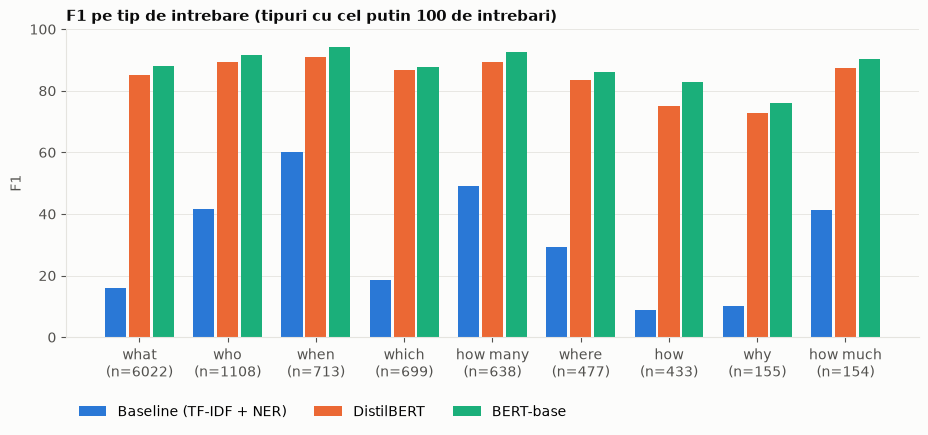

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(qtypes))
width = 0.27
for i, (name, color) in enumerate(zip(MODELS, COLORS)):
    ax.bar(x + (i - 1) * width, f1_by_type[name], width - 0.03, color=color, label=name)
ax.set_xticks(x, [f"{q}\n(n={counts[q]})" for q in qtypes])
ax.set_ylabel("F1")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
ax.set_title("F1 pe tip de intrebare (tipuri cu cel putin 100 de intrebari)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.18), ncol=3)
fig.savefig(FIG_DIR / "results_f1_by_question_type.png")
plt.show()

## 3. Pe lungimea pasajului (cuvinte)

In [5]:
length_order = ["<100", "100-149", "150-199", ">=200"]
f1_by_length = table_by("by_context_length", "f1").loc[length_order]
f1_by_length.round(1)

,Baseline (TF-IDF + NER),DistilBERT,BERT-base
<100,25.1,85.3,88.0
100-149,24.6,85.8,89.2
150-199,24.4,85.1,88.6
>=200,23.3,86.1,87.7


## 4. Retriever: Recall@k

Corpus: 2.067 paragrafe unice din validation; pentru fiecare din cele 10.570 de intrebari, Recall@k = paragraful din care provine intrebarea e in top-k.

In [6]:
retriever = json.loads(Path("results/retriever_metrics.json").read_text(encoding="utf-8"))
unigram = json.loads(Path("results/retriever_tfidf_unigram_metrics.json").read_text(encoding="utf-8"))["tfidf"]
RETRIEVERS = {"TF-IDF (1-2 grame)": retriever["tfidf"], "TF-IDF (unigrame)": unigram, "BM25": retriever["bm25"]}

recall = pd.DataFrame({name: m["recall"] for name, m in RETRIEVERS.items()}).T
recall["MRR"] = [m["mrr"] for m in RETRIEVERS.values()]
article = pd.DataFrame({name: m["article_recall"] for name, m in RETRIEVERS.items()}).T.add_prefix("articol ")
pd.concat([recall, article[["articol @1", "articol @5"]]], axis=1)

,@1,@3,@5,@10,@20,MRR,articol @1,articol @5
TF-IDF (1-2 grame),72.12,86.10,89.89,93.60,96.14,0.8005,92.59,98.45
TF-IDF (unigrame),69.65,84.99,89.44,93.47,96.22,0.7841,92.00,98.20
BM25,75.05,87.95,91.37,94.38,96.52,0.8232,93.86,98.51


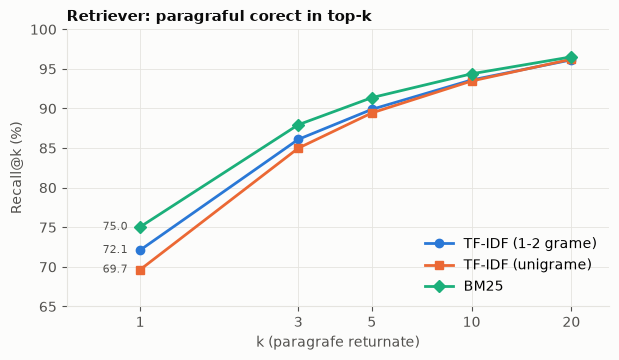

In [7]:
ks = [int(k[1:]) for k in retriever["bm25"]["recall"]]
fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, m), color, marker in zip(RETRIEVERS.items(), COLORS, ["o", "s", "D"]):
    values = list(m["recall"].values())
    ax.plot(ks, values, color=color, linewidth=2, marker=marker, markersize=6, label=name)
    ax.annotate(f"{values[0]:.1f}", (ks[0], values[0]), textcoords="offset points", xytext=(-9, 0), ha="right", va="center", fontsize=8, color=INK_MUTED)
ax.set_xscale("log")
ax.set_xlim(0.6, 26)
ax.set_xticks(ks, [str(k) for k in ks])
ax.minorticks_off()
ax.set_xlabel("k (paragrafe returnate)")
ax.set_ylabel("Recall@k (%)")
ax.set_ylim(65, 100)
ax.set_title("Retriever: paragraful corect in top-k")
ax.legend(loc="lower right")
fig.savefig(FIG_DIR / "results_retriever_recall.png")
plt.show()

## 5. Pipeline open-domain (BM25 + DistilBERT)

500 de intrebari din validation (seed 42). Pentru fiecare: BM25 aduce top-k paragrafe, reader-ul le citeste pe toate, raspunsul final e cel cu scorul maxim al reader-ului. Linia punctata = acelasi reader cu paragraful corect dat (limita superioara).

In [8]:
pipeline = json.loads(Path("results/pipeline_bm25_distilbert-base-uncased-squad_metrics.json").read_text(encoding="utf-8"))
pipe_ks = [int(key[3:]) for key in pipeline if key.startswith("top")]
pipe = pd.DataFrame({
    f"top-{k}": {
        "EM": pipeline[f"top{k}"]["exact_match"],
        "F1": pipeline[f"top{k}"]["f1"],
        "Recall@k BM25": pipeline[f"top{k}"]["retrieval_recall"],
        "raspuns din paragraful corect": pipeline[f"top{k}"]["answer_from_gold_paragraph"],
    } for k in pipe_ks
}).T
pipe.loc["paragraf corect dat"] = [pipeline["gold_paragraph"]["exact_match"], pipeline["gold_paragraph"]["f1"], 100.0, 100.0]
pipe

,EM,F1,Recall@k BM25,raspuns din paragraful corect
top-1,57.2,65.75,75.8,75.8
top-3,61.2,68.96,86.2,76.6
top-5,61.2,69.11,89.4,74.0
top-10,62.8,69.84,94.0,74.6
paragraf corect dat,74.6,83.59,100.0,100.0


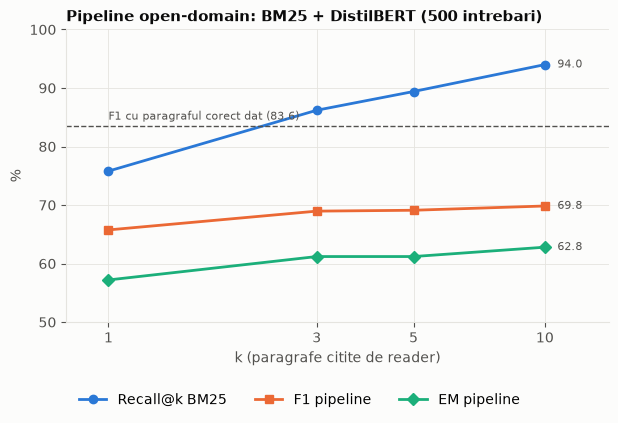

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8))
series = {
    "Recall@k BM25": [pipeline[f"top{k}"]["retrieval_recall"] for k in pipe_ks],
    "F1 pipeline": [pipeline[f"top{k}"]["f1"] for k in pipe_ks],
    "EM pipeline": [pipeline[f"top{k}"]["exact_match"] for k in pipe_ks],
}
for (name, values), color, marker in zip(series.items(), COLORS, ["o", "s", "D"]):
    ax.plot(pipe_ks, values, color=color, linewidth=2, marker=marker, markersize=6, label=name)
    ax.annotate(f"{values[-1]:.1f}", (pipe_ks[-1], values[-1]), textcoords="offset points", xytext=(9, 0),
                va="center", fontsize=8, color=INK_MUTED)
gold_f1 = pipeline["gold_paragraph"]["f1"]
ax.axhline(gold_f1, color=INK_MUTED, linewidth=1, linestyle="--")
ax.text(pipe_ks[0], gold_f1 + 1, f"F1 cu paragraful corect dat ({gold_f1:.1f})", fontsize=8, color=INK_MUTED)
ax.set_xscale("log")
ax.set_xlim(0.8, 14)
ax.set_xticks(pipe_ks, [str(k) for k in pipe_ks])
ax.minorticks_off()
ax.set_ylim(50, 100)
ax.set_xlabel("k (paragrafe citite de reader)")
ax.set_ylabel("%")
ax.set_title("Pipeline open-domain: BM25 + DistilBERT (500 intrebari)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.2), ncol=3)
fig.savefig(FIG_DIR / "results_pipeline_topk.png")
plt.show()

## 6. Observatii

- BERT-base > DistilBERT > baseline pe toate tipurile de intrebari. Diferenta BERT-base vs DistilBERT e de ~3-4 puncte EM/F1, la un model de ~2x mai mic si ~2x mai rapid.
- Cel mai mare castig fata de baseline e pe "what" / "which" / "how" / "why", unde baseline-ul nu are o entitate de cautat; pe "when" si "how many" baseline-ul era deja decent datorita regulilor NER.
- "why" si "how" raman cele mai grele si pentru BERT (raspunsuri lungi, explicative, cu granite ambigue): EM ~50-68, dar F1 mult mai mare (72-83), deci modelul gaseste zona corecta dar nu exact span-ul de referinta.
- Lungimea pasajului aproape nu conteaza pentru reader (variatie < 1,5 puncte F1), ceea ce confirma ca sliding window-ul nu pierde informatie.
- Retriever: BM25 > TF-IDF la toate valorile k (R@1 75,0 vs 72,1), diferenta se inchide la k=20 (~96,5 ambele). Bigramele ajuta TF-IDF (+2,4 R@1).
- Articolul corect e gasit in top-1 in ~93% din cazuri: erorile retriever-ului sunt mai ales confuzii intre paragrafe ale aceluiasi articol.
- Recall-ul e mare si pentru ca intrebarile SQuAD au fost scrise privind paragraful (suprapunere lexicala mare); intr-un scenariu open-domain real ar fi mai mic.
- Pipeline: F1 creste de la 65,8 (k=1) la 69,8 (k=10), dar ramane ~14 puncte sub reader-ul cu paragraful corect (83,6). Recall-ul BM25 urca la 94% la k=10, insa raspunsul vine din paragraful corect doar in ~75% din cazuri la orice k: cu mai multe paragrafe, reader-ul e "pacalit" de paragrafe vecine din acelasi articol, iar scorurile lui nu sunt calibrate intre paragrafe.